# 03. Basic models and strong tabular baselines

Question: to what extent can the first run be predicted from the learner's history and the description of the next task? All models use the same sample, identical group folds and the target definition from the first two notebooks.

The primary metric is LogLoss (lower is better); the secondary metrics are AUROC and average precision (higher is better) and Brier (lower is better). Two prespecified tuning variants of each trainable family are compared by pooled OOF LogLoss over three learner folds, seed 17. The selected configuration is evaluated with seeds 17, 42, 2026. Imputation, scaling and encoding are refitted within each training fold.

OOF predictions are used for configuration selection and subsequent stacking; they are not an independent post-tuning estimate. The validation set contains different learners and serves to compare families. The locked test is not loaded. The sample is not rebalanced: predictions must preserve the observed outcome frequency.

In [1]:
from pathlib import Path
import json
import hashlib
import urllib.request
import urllib.error
import platform


def verify_frozen_training_source(root: Path) -> None:
    """Allow exact-source reproduction without pretending a viewed test is new."""
    boundary = root / "Protocol/test_evaluation_boundary.json"
    if not boundary.exists():
        return
    frozen_sources = json.loads(
        (root / "Protocol/frozen_training_sources.json").read_text()
    )
    for filename, expected in frozen_sources["notebooks"].items():
        notebook = json.loads((root / "Notebooks" / filename).read_text())
        source = "\n\n".join(
            "".join(cell["source"])
            for cell in notebook["cells"]
            if cell["cell_type"] == "code"
        )
        observed = hashlib.sha256(source.encode()).hexdigest()
        assert (
            observed == expected
        ), "Training source changed after the test was opened."


from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown

ROOT = Path.cwd() if (Path.cwd() / "Data").exists() else Path.cwd().parent
assert ROOT.name == "ALPHA"
SEED = 20260923
rng = np.random.default_rng(SEED)
font_names = {font.name for font in font_manager.fontManager.ttflist}
assert "Times New Roman" in font_names
FONT = "Times New Roman"
FONT_SIZE, TITLE_SIZE, FIGURE_DPI = 18, 20, 350
mpl.rcParams.update(
    {
        "font.family": FONT,
        "font.size": 18,
        "axes.titlesize": 20,
        "axes.labelsize": 18,
        "xtick.labelsize": 18,
        "ytick.labelsize": 18,
        "legend.fontsize": 18,
        "figure.dpi": 350,
        "savefig.dpi": 350,
        "axes.unicode_minus": True,
        "mathtext.fontset": "stix",
    }
)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)


def table(frame: pd.DataFrame, caption: str, name: str) -> None:
    """Display a complete DataFrame using Jupyter's default table styling."""
    frame.to_csv(ROOT / "Tables" / f"{name}.csv", index=False)
    with pd.option_context(
        "display.max_rows",
        None,
        "display.max_columns",
        None,
        "display.max_colwidth",
        None,
        "display.width",
        None,
    ):
        display(Markdown(caption))
        display(frame.reset_index(drop=True).round(3))


def save_figure(fig: mpl.figure.Figure, name: str) -> None:
    """Save at 350 dpi after checking the font contract on visible text."""
    from matplotlib.text import Text

    fig.canvas.draw()
    for text in fig.findobj(match=Text):
        if text.get_visible() and text.get_text():
            assert 18 <= text.get_fontsize() <= 20
            assert text.get_fontfamily() == ["Times New Roman"]
    fig.savefig(ROOT / "Figures" / f"{name}.png", dpi=FIGURE_DPI)
    fig.savefig(ROOT / "Figures" / f"{name}.pdf", dpi=FIGURE_DPI)


import time
import joblib
from typing import Any
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (
    log_loss,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.calibration import calibration_curve
from sklearn.base import clone
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

protocol = json.loads(
    (ROOT / "Protocol/robomission_protocol.json").read_text()
)
verify_frozen_training_source(ROOT)
verify_frozen_training_source(ROOT)
assert (
    not protocol["locked_test_opened"]
    or (ROOT / "Protocol/test_evaluation_boundary.json").exists()
    or (ROOT / "Protocol/test_evaluation_boundary.json").exists()
)
contract = json.loads(
    (ROOT / "Protocol/robo_feature_contract.json").read_text()
)
train_data = pd.read_pickle(
    ROOT / "Data/Processed/robo_features_train.pkl"
).reset_index(drop=True)
validation_data = pd.read_pickle(
    ROOT / "Data/Processed/robo_features_validation.pkl"
).reset_index(drop=True)
feature_names = contract["features"]
numeric_names = [
    name for name in feature_names if name not in contract["categorical"]
]
assert set(train_data.student).isdisjoint(validation_data.student)
assert train_data.groupby("student").fold.nunique().eq(1).all()
MODEL_DIR = ROOT / "Results/baselines"
MODEL_DIR.mkdir(exist_ok=True)
SEEDS = [17, 42, 2026]
PROBABILITY_EPSILON = 1e-6
CANDIDATES = {
    "LogisticRegression": [{"C": 0.1}, {"C": 1.0}],
    "RandomForest": [{"max_depth": 8}, {"max_depth": 14}],
    "XGBoost": [{"max_depth": 3}, {"max_depth": 5}],
    "LightGBM": [{"num_leaves": 15}, {"num_leaves": 31}],
}
selected_configurations, candidate_predictions = {}, {}
selection_rows, efficiency_rows = [], []
all_predictions, all_metrics = [], []

assert contract["feature_revision"] == "event_prefix_v2"
assert (
    train_data.attrs["feature_revision"]
    == validation_data.attrs["feature_revision"]
    == "event_prefix_v2"
)

## Implementation of the common protocol

The functions below execute the same procedure for all families. The learner identifier is not a model input. Training and validation rows retain their original identifiers for subsequent paired comparisons.

In [2]:
def probability_metrics(
    target: np.ndarray, probability: np.ndarray
) -> dict[str, float]:
    """Calculate prespecified classification metrics on finite probabilities."""
    assert np.isfinite(probability).all()
    assert np.logical_and(probability >= 0, probability <= 1).all()
    clipped = np.clip(
        probability, PROBABILITY_EPSILON, 1 - PROBABILITY_EPSILON
    )
    return {
        "LogLoss": log_loss(target, clipped, labels=[0, 1]),
        "AUROC": roc_auc_score(target, clipped),
        "AP": average_precision_score(target, clipped),
        "Brier": brier_score_loss(target, clipped),
    }


def make_preprocessor() -> ColumnTransformer:
    """Create a fresh fold-local numerical and categorical transformation."""
    numeric = make_pipeline(
        SimpleImputer(strategy="median", add_indicator=True), StandardScaler()
    )
    categorical = OneHotEncoder(
        handle_unknown="ignore", sparse_output=False, dtype=np.float32
    )
    return ColumnTransformer(
        [
            ("numeric", numeric, numeric_names),
            ("task", categorical, ["problem"]),
        ],
        sparse_threshold=0,
    )


def transformed_frame(values: np.ndarray) -> pd.DataFrame:
    """Use stable neutral column names for all estimator implementations."""
    return pd.DataFrame(
        values.astype(np.float32),
        columns=[f"x{i:03d}" for i in range(values.shape[1])],
    )


def make_estimator(model_name: str, settings: dict, seed: int) -> Any:
    """Construct one model under the declared fixed training budget."""
    if model_name == "LogisticRegression":
        return LogisticRegression(
            **settings,
            solver="lbfgs",
            max_iter=2000,
            tol=1e-5,
            random_state=seed,
        )
    if model_name == "RandomForest":
        return RandomForestClassifier(
            **settings,
            n_estimators=120,
            min_samples_leaf=20,
            n_jobs=2,
            random_state=seed,
        )
    if model_name == "XGBoost":
        return XGBClassifier(
            **settings,
            n_estimators=220,
            learning_rate=0.05,
            subsample=0.9,
            colsample_bytree=0.9,
            reg_lambda=2,
            tree_method="hist",
            n_jobs=2,
            random_state=seed,
            verbosity=0,
        )
    if model_name == "LightGBM":
        return LGBMClassifier(
            **settings,
            n_estimators=220,
            learning_rate=0.05,
            min_child_samples=30,
            reg_lambda=2,
            colsample_bytree=0.9,
            n_jobs=2,
            random_state=seed,
            verbosity=-1,
            deterministic=True,
            force_col_wise=True,
        )
    raise ValueError(f"Unknown model: {model_name}")


def crossfit(
    model_name: str, settings: dict, seed: int
) -> tuple[np.ndarray, float]:
    """Predict each training learner using models fitted on other learners."""
    out_of_fold = np.full(len(train_data), np.nan)
    seconds = 0.0
    for fold in sorted(train_data.fold.unique()):
        held_out = train_data.fold.eq(fold).to_numpy()
        fit_rows, held_rows = (
            train_data.loc[~held_out],
            train_data.loc[held_out],
        )
        assert set(fit_rows.student).isdisjoint(held_rows.student)
        preprocessing = make_preprocessor()
        started = time.perf_counter()
        fit_matrix = transformed_frame(
            preprocessing.fit_transform(fit_rows[feature_names])
        )
        held_matrix = transformed_frame(
            preprocessing.transform(held_rows[feature_names])
        )
        estimator = make_estimator(model_name, settings, seed)
        estimator.fit(fit_matrix, fit_rows.y.to_numpy())
        seconds += time.perf_counter() - started
        out_of_fold[held_out] = estimator.predict_proba(held_matrix)[:, 1]
    assert np.isfinite(out_of_fold).all()
    return out_of_fold, seconds


def tune_family(model_name: str) -> pd.DataFrame:
    """Compare two fixed candidates and retain their complete OOF predictions."""
    rows = []
    for candidate, settings in enumerate(CANDIDATES[model_name]):
        predicted, seconds = crossfit(model_name, settings, SEEDS[0])
        candidate_predictions[(model_name, candidate)] = predicted
        metrics = probability_metrics(train_data.y.to_numpy(), predicted)
        rows.append(
            {
                "Model": model_name,
                "Split": "Train OOF",
                "n": len(train_data),
                "Candidate": candidate,
                "Configuration": json.dumps(settings),
                "LogLoss ↓": metrics["LogLoss"],
                "Brier ↓": metrics["Brier"],
            }
        )
        selection_rows.append(
            {
                "model": model_name,
                "candidate": candidate,
                "settings": settings,
                "oof_seconds": seconds,
                **metrics,
            }
        )
    best = min(rows, key=lambda row: row["LogLoss ↓"])["Candidate"]
    selected_configurations[model_name] = CANDIDATES[model_name][best]
    return pd.DataFrame(rows)


def record_predictions(
    model_name: str,
    split: str,
    seed: int,
    rows: pd.DataFrame,
    probability: np.ndarray,
) -> None:
    """Keep aligned predictions and exact per-seed metrics for downstream analysis."""
    prediction = rows[["id", "student", "problem", "y", "fold"]].copy()
    prediction["model"], prediction["split"], prediction["seed"] = (
        model_name,
        split,
        seed,
    )
    prediction["probability"] = probability
    all_predictions.append(prediction)
    all_metrics.append(
        {
            "Model": model_name,
            "Split": split,
            "Seed": seed,
            "n": len(rows),
            **probability_metrics(rows.y.to_numpy(), probability),
        }
    )

## Simple probabilistic baselines

How useful are the overall success rate and task difficulty without the learner's history? The task-level estimate is shrunk towards the overall rate with a prespecified weight of 20 observations. In all OOF predictions, the rates are computed without the fold being evaluated.

In [3]:
ITEM_PRIOR_WEIGHT = 20.0
simple_rows = []
for model_name in ["GlobalMean", "ItemMean"]:
    oof = np.full(len(train_data), np.nan)
    for fold in sorted(train_data.fold.unique()):
        held_out = train_data.fold.eq(fold)
        fitting = train_data.loc[~held_out]
        prior = float(fitting.y.mean())
        grouped = fitting.groupby("problem").y.agg(["sum", "count"])
        rates = (grouped["sum"] + ITEM_PRIOR_WEIGHT * prior) / (
            grouped["count"] + ITEM_PRIOR_WEIGHT
        )
        oof[held_out] = (
            train_data.loc[held_out, "problem"].map(rates).fillna(prior)
            if model_name == "ItemMean"
            else prior
        )
    prior = float(train_data.y.mean())
    grouped = train_data.groupby("problem").y.agg(["sum", "count"])
    rates = (grouped["sum"] + ITEM_PRIOR_WEIGHT * prior) / (
        grouped["count"] + ITEM_PRIOR_WEIGHT
    )
    validation_probability = (
        validation_data.problem.map(rates).fillna(prior).to_numpy()
        if model_name == "ItemMean"
        else np.full(len(validation_data), prior)
    )
    for split, frame, probability in [
        ("Train OOF", train_data, oof),
        ("Validation", validation_data, validation_probability),
    ]:
        record_predictions(model_name, split, SEEDS[0], frame, probability)
        metric = probability_metrics(frame.y.to_numpy(), probability)
        simple_rows.append(
            {
                "Model": model_name,
                "Split": split,
                "n": len(frame),
                "LogLoss ↓": metric["LogLoss"],
                "Brier ↓": metric["Brier"],
            }
        )
    joblib.dump(
        {
            "prior": prior,
            "rates": rates,
            "item_prior_weight": ITEM_PRIOR_WEIGHT,
        },
        MODEL_DIR / f"{model_name}.joblib",
    )
table(
    pd.DataFrame(simple_rows),
    "Table 1. Simple baselines: probabilistic quality",
    "03_simple_baselines",
)

Table 1. Simple baselines: probabilistic quality

,Model,Split,n,LogLoss ↓,Brier ↓
0,GlobalMean,Train OOF,108877,0.684,0.246
1,GlobalMean,Validation,23326,0.684,0.245
2,ItemMean,Train OOF,108877,0.591,0.203
3,ItemMean,Validation,23326,0.589,0.202


**Interpretation.** Accounting for the task reduces validation LogLoss from 0.684 to 0.589. Hence, unequal task difficulty alone explains a substantial part of the predictability; any complex model must outperform this baseline.

## LogisticRegression

Is an additive model of history and task sufficient after fold-local standardisation? Tuning uses only the training folds; the full results for both candidates are shown here.

In [4]:
table(
    tune_family("LogisticRegression"),
    "Table 2. LogisticRegression: configuration selection",
    "03_tuning_logisticregression",
)

Table 2. LogisticRegression: configuration selection

,Model,Split,n,Candidate,Configuration,LogLoss ↓,Brier ↓
0,LogisticRegression,Train OOF,108877,0,"{""C"": 0.1}",0.553,0.187
1,LogisticRegression,Train OOF,108877,1,"{""C"": 1.0}",0.553,0.187


**Interpretation.** Within the explored grid, C = 1.0 yields the lower OOF LogLoss. The improvement over ItemMean confirms the usefulness of history and context features; this is a result of configuration selection, not an independent final estimate.

## RandomForest

Are non-linear thresholds and interactions useful when tree depth is limited? Tuning uses only the training folds; the full results for both candidates are shown here.

In [5]:
table(
    tune_family("RandomForest"),
    "Table 3. RandomForest: configuration selection",
    "03_tuning_randomforest",
)

Table 3. RandomForest: configuration selection

,Model,Split,n,Candidate,Configuration,LogLoss ↓,Brier ↓
0,RandomForest,Train OOF,108877,0,"{""max_depth"": 8}",0.568,0.193
1,RandomForest,Train OOF,108877,1,"{""max_depth"": 14}",0.547,0.185


**Interpretation.** Depth 14 outperforms depth 8 within the limited random-forest grid. The advantage over the linear model indicates the usefulness of a non-linear representation but does not prove that the identified relationships are causal.

## XGBoost

How well does sequential gradient boosting generalise with the same number of trees and two depths? Tuning uses only the training folds; the full results for both candidates are shown here.

In [6]:
table(
    tune_family("XGBoost"),
    "Table 4. XGBoost: configuration selection",
    "03_tuning_xgboost",
)

Table 4. XGBoost: configuration selection

,Model,Split,n,Candidate,Configuration,LogLoss ↓,Brier ↓
0,XGBoost,Train OOF,108877,0,"{""max_depth"": 3}",0.549,0.186
1,XGBoost,Train OOF,108877,1,"{""max_depth"": 5}",0.537,0.181


**Interpretation.** Depth 5 reduces OOF LogLoss compared with depth 3. This setting is fixed for the repeated seeds; the number of trees and the remaining parameters are not tuned on the locked test.

## LightGBM

Does a different tree-construction algorithm improve the result with the same number of boosting steps? Tuning uses only the training folds; the full results for both candidates are shown here.

In [7]:
table(
    tune_family("LightGBM"),
    "Table 5. LightGBM: configuration selection",
    "03_tuning_lightgbm",
)

Table 5. LightGBM: configuration selection

,Model,Split,n,Candidate,Configuration,LogLoss ↓,Brier ↓
0,LightGBM,Train OOF,108877,0,"{""num_leaves"": 15}",0.538,0.182
1,LightGBM,Train OOF,108877,1,"{""num_leaves"": 31}",0.535,0.180


**Interpretation.** LightGBM with 31 leaves yields a lower OOF LogLoss than the variant with 15 leaves. This configuration is carried forward to the repeated fits and to the comparison on validation, which is external to train.

## Refitting the selected configurations

How stable are the selected families across three seeds? For seed 17, the already computed OOF predictions of the selected candidate are reused; for the remaining seeds, the same three-fold procedure is performed. The final instances are trained on the full train set and predict validation. Neither validation nor test participates in imputation or in the estimation of model parameters.

In [8]:
for model_name, settings in selected_configurations.items():
    chosen = next(
        i
        for i, candidate in enumerate(CANDIDATES[model_name])
        if candidate == settings
    )
    for seed in SEEDS:
        if seed == SEEDS[0]:
            oof = candidate_predictions[(model_name, chosen)]
        else:
            oof, _ = crossfit(model_name, settings, seed)
        record_predictions(model_name, "Train OOF", seed, train_data, oof)
        preprocessing = make_preprocessor()
        started = time.perf_counter()
        fit_matrix = transformed_frame(
            preprocessing.fit_transform(train_data[feature_names])
        )
        validation_matrix = transformed_frame(
            preprocessing.transform(validation_data[feature_names])
        )
        estimator = make_estimator(model_name, settings, seed)
        estimator.fit(fit_matrix, train_data.y.to_numpy())
        training_seconds = time.perf_counter() - started
        started = time.perf_counter()
        probability = estimator.predict_proba(validation_matrix)[:, 1]
        prediction_seconds = time.perf_counter() - started
        record_predictions(
            model_name, "Validation", seed, validation_data, probability
        )
        destination = MODEL_DIR / f"{model_name}_{seed}.joblib"
        joblib.dump(
            {
                "preprocessing": preprocessing,
                "estimator": estimator,
                "features": feature_names,
                "settings": settings,
                "seed": seed,
            },
            destination,
        )
        efficiency_rows.append(
            {
                "Model": model_name,
                "Split": "Validation",
                "Seed": seed,
                "n": len(validation_data),
                "Train seconds": training_seconds,
                "Prediction seconds": prediction_seconds,
                "Model MB": destination.stat().st_size / 1e6,
            }
        )
prediction_frame = pd.concat(all_predictions, ignore_index=True)
metric_frame = pd.DataFrame(all_metrics)
prediction_frame.attrs["feature_revision"] = contract["feature_revision"]
prediction_frame.to_pickle(ROOT / "Results/03_baseline_predictions.pkl")
metric_frame.to_csv(ROOT / "Tables/03_per_seed_metrics.csv", index=False)
pd.DataFrame(efficiency_rows).to_csv(
    ROOT / "Tables/03_efficiency.csv", index=False
)
(ROOT / "Protocol/baseline_configurations.json").write_text(
    json.dumps(selected_configurations, indent=2)
)
pd.DataFrame(selection_rows).to_json(
    ROOT / "Results/03_tuning.json", orient="records", indent=2
)
probability_summary = (
    metric_frame.groupby(["Model", "Split", "n"], sort=False)
    .agg(
        LogLoss=("LogLoss", "mean"),
        LogLoss_SD=("LogLoss", "std"),
        Brier=("Brier", "mean"),
    )
    .reset_index()
)
probability_summary = probability_summary.rename(
    columns={
        "LogLoss": "LogLoss ↓",
        "LogLoss_SD": "Seed SD",
        "Brier": "Brier ↓",
    }
)
table(
    probability_summary,
    "Table 6. Probabilistic quality and spread across seeds",
    "03_probability_quality",
)

Table 6. Probabilistic quality and spread across seeds

,Model,Split,n,LogLoss ↓,Seed SD,Brier ↓
0,GlobalMean,Train OOF,108877,0.684,NaN,0.246
1,GlobalMean,Validation,23326,0.684,NaN,0.245
2,ItemMean,Train OOF,108877,0.591,NaN,0.203
3,ItemMean,Validation,23326,0.589,NaN,0.202
4,LogisticRegression,Train OOF,108877,0.553,0.000,0.187
5,LogisticRegression,Validation,23326,0.550,0.000,0.185
6,RandomForest,Train OOF,108877,0.547,0.000,0.185
7,RandomForest,Validation,23326,0.542,0.001,0.182
8,XGBoost,Train OOF,108877,0.537,0.000,0.181
9,XGBoost,Validation,23326,0.533,0.000,0.179


**Interpretation.** After three seeds, LightGBM has the best mean validation LogLoss among the tabular models (about 0.531), followed by XGBoost (about 0.533). Seed SD describes optimisation variation; a displayed value of 0.000 after rounding does not mean mathematically zero variation. For deterministic baselines, repeated seeds have no independent meaning, so SD is absent.

## Discriminative ability

Probabilistic quality and ranking answer different questions. AUROC and AP below are computed on the same rows and seeds. Deterministic baselines have a single result; the absent between-seed variability is not replaced by an experimentally measured zero.

In [9]:
ranking_summary = (
    metric_frame.groupby(["Model", "Split", "n"], sort=False)
    .agg(AUROC=("AUROC", "mean"), AP=("AP", "mean"))
    .reset_index()
    .rename(columns={"AUROC": "AUROC ↑", "AP": "AP ↑"})
)
table(
    ranking_summary,
    "Table 7. Ranking quality on a comparable sample",
    "03_ranking_quality",
)

Table 7. Ranking quality on a comparable sample

,Model,Split,n,AUROC ↑,AP ↑
0,GlobalMean,Train OOF,108877,0.496,0.431
1,GlobalMean,Validation,23326,0.500,0.432
2,ItemMean,Train OOF,108877,0.738,0.634
3,ItemMean,Validation,23326,0.741,0.634
4,LogisticRegression,Train OOF,108877,0.784,0.711
5,LogisticRegression,Validation,23326,0.788,0.716
6,RandomForest,Train OOF,108877,0.792,0.724
7,RandomForest,Validation,23326,0.798,0.732
8,XGBoost,Train OOF,108877,0.798,0.730
9,XGBoost,Validation,23326,0.804,0.738


**Interpretation.** LightGBM also has the best mean validation AUROC (about 0.805) and AP (about 0.739) among the baselines considered. Thus, selection by LogLoss is not accompanied here by a deterioration in ranking metrics. The pooled OOF AUROC of GlobalMean may differ slightly from 0.5 because the training folds have different constants.

## Calibration of strong baselines

Do the predicted probabilities match the observed frequencies? The task baseline, logistic regression and the best tree model by mean validation LogLoss are shown. The figure uses the mean predictions of three seeds; it does not replace the tables of mean metrics of individual runs.

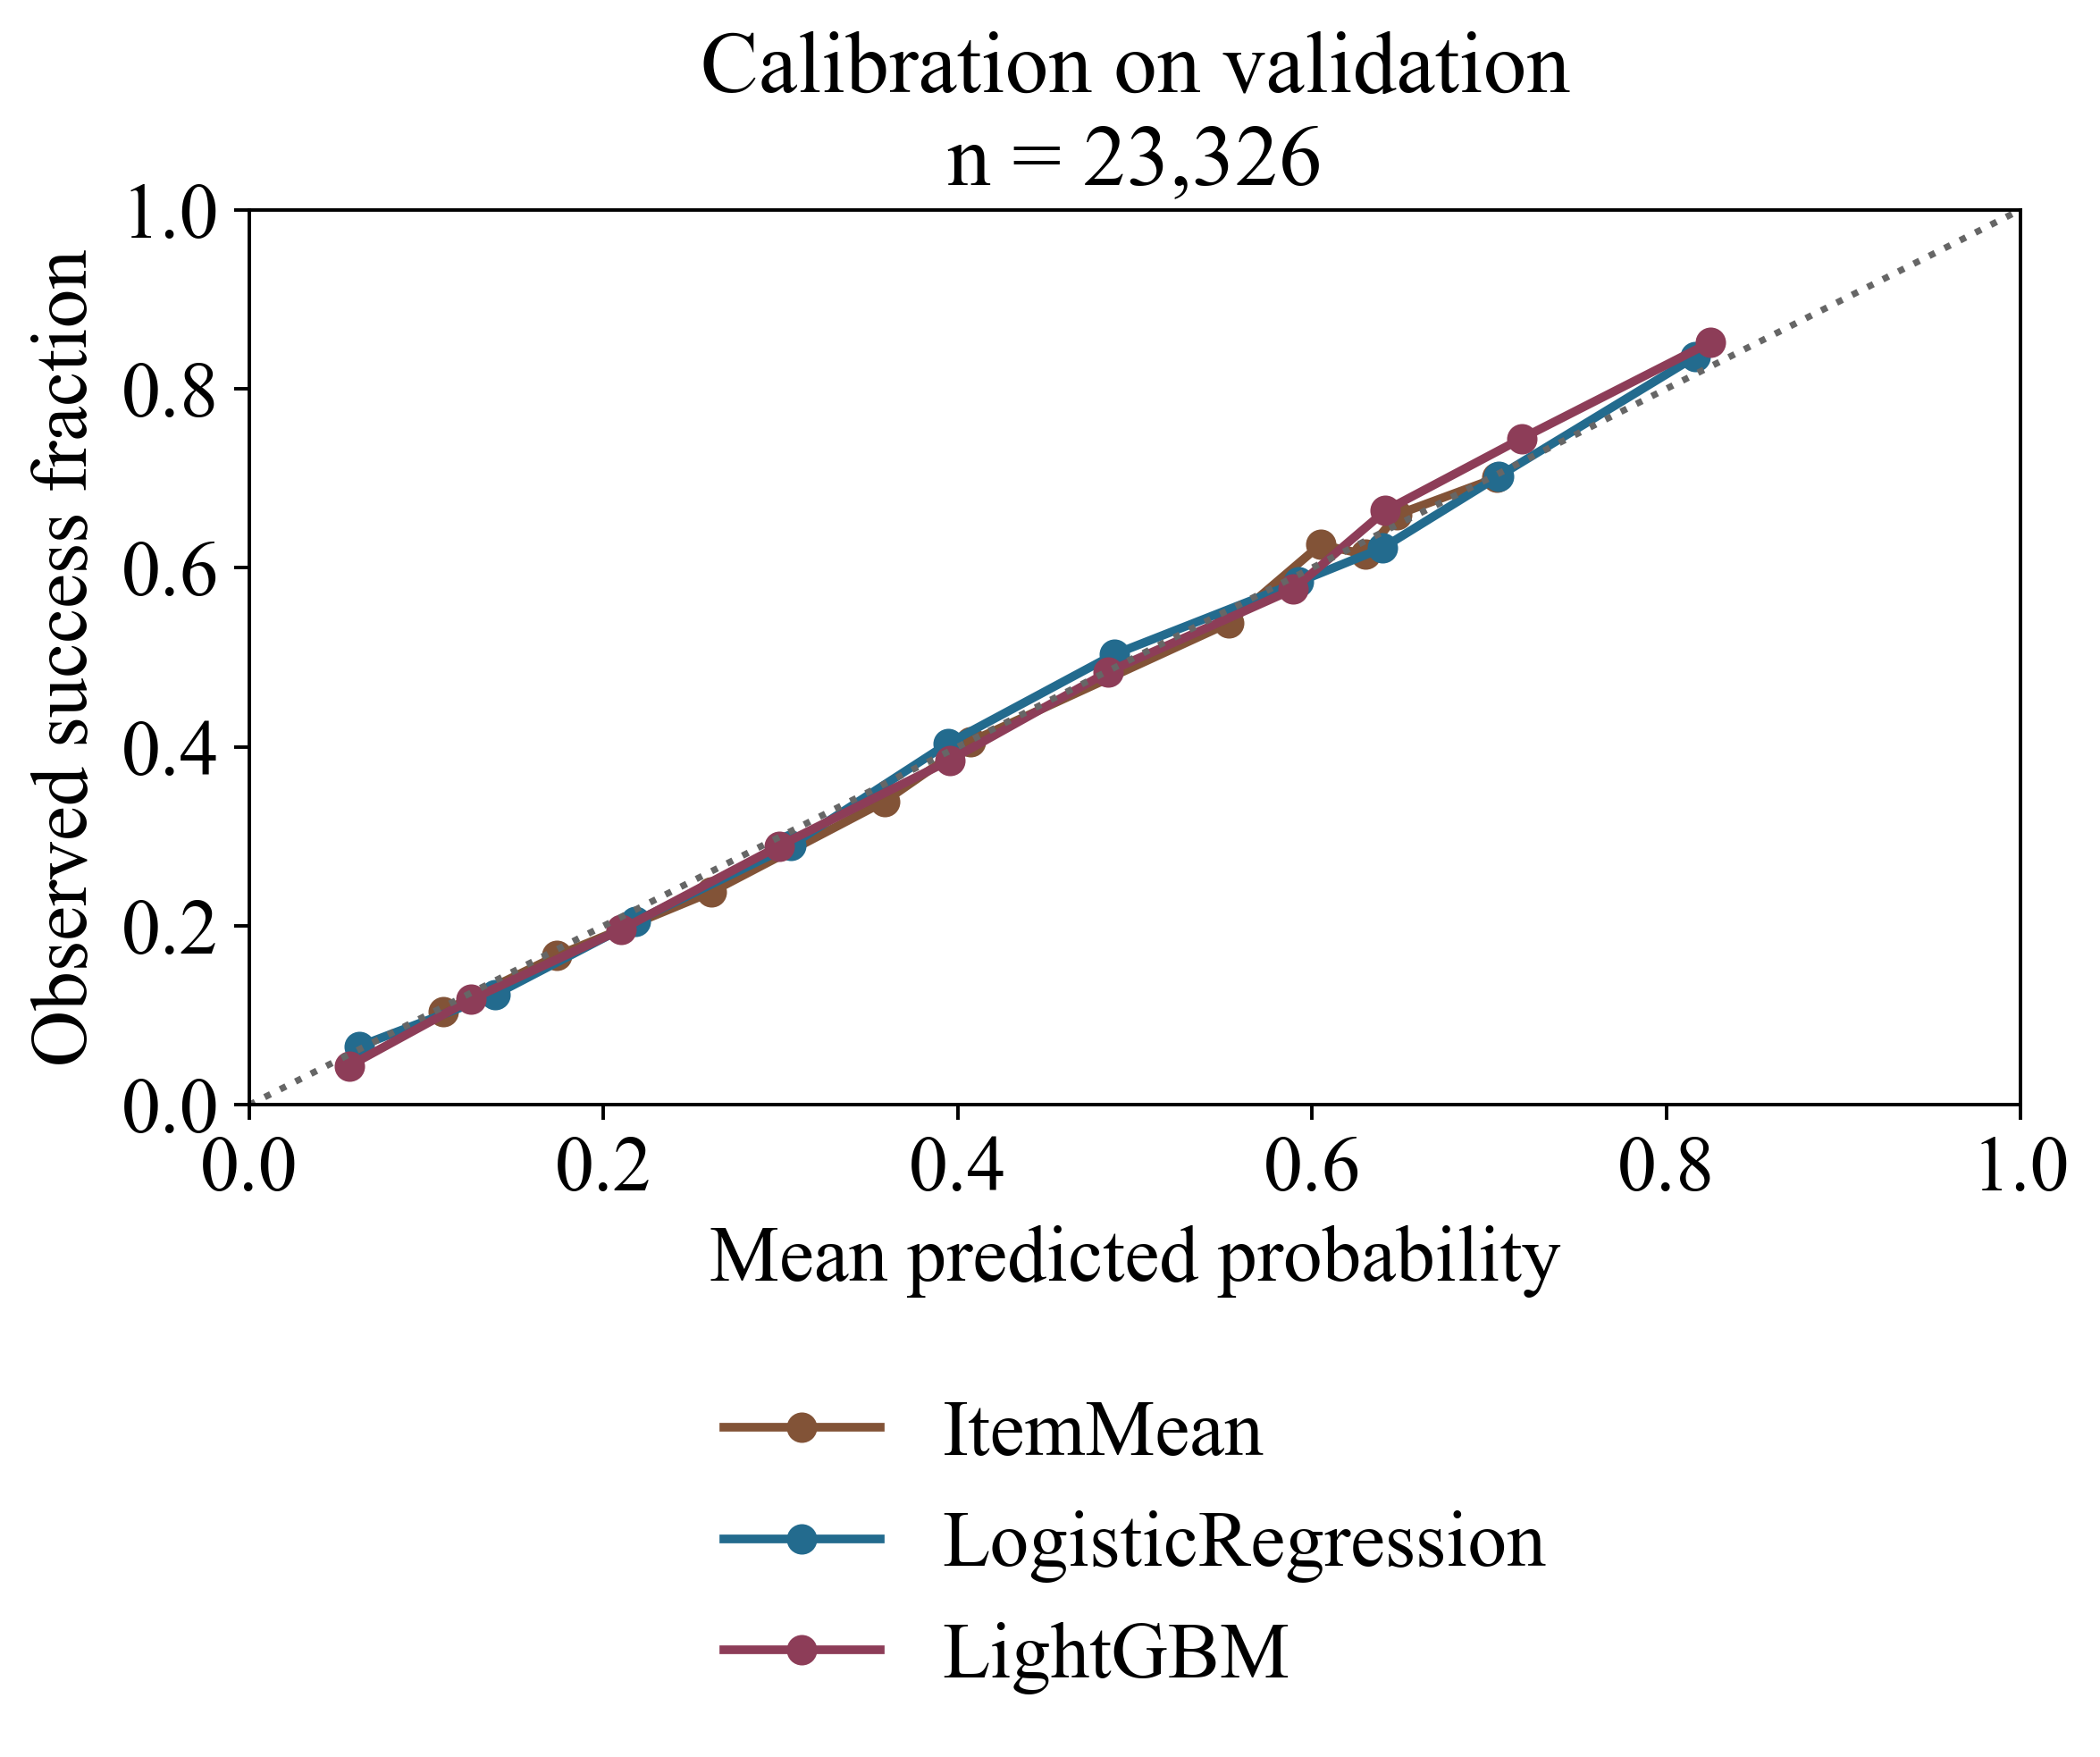

In [10]:
validation_metrics = metric_frame[metric_frame.Split.eq("Validation")]
mean_loss = validation_metrics.groupby("Model").LogLoss.mean()
best_tree = mean_loss.loc[["RandomForest", "XGBoost", "LightGBM"]].idxmin()
DIAGNOSTIC_MODELS = ["ItemMean", "LogisticRegression", best_tree]
COLORS = ["#825337", "#236B8E", "#8D3D58"]
ensemble_validation = (
    prediction_frame[prediction_frame.split.eq("Validation")]
    .groupby(["model", "id"], sort=False)
    .probability.mean()
)
fig, ax = plt.subplots(figsize=(6.6, 5.5), layout="constrained")
calibration_rows = []
for model_name, color in zip(DIAGNOSTIC_MODELS, COLORS):
    probability = (
        ensemble_validation.loc[model_name]
        .reindex(validation_data.id)
        .to_numpy()
    )
    observed, predicted = calibration_curve(
        validation_data.y, probability, n_bins=10, strategy="quantile"
    )
    ax.plot(
        predicted,
        observed,
        marker="o",
        color=color,
        linewidth=2,
        label=model_name,
    )
    calibration_rows.extend(
        {"Model": model_name, "Predicted": p, "Observed": o}
        for p, o in zip(predicted, observed)
    )
ax.plot([0, 1], [0, 1], linestyle=":", color="#666666")
ax.set(
    xlabel="Mean predicted probability",
    ylabel="Observed success fraction",
    title=f"Calibration on validation\nn = {len(validation_data):,}",
    xlim=(0, 1),
    ylim=(0, 1),
)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False)
pd.DataFrame(calibration_rows).to_csv(
    ROOT / "Tables/03_calibration_curve.csv", index=False
)
save_figure(fig, "03_calibration")
plt.show()

**Interpretation.** The curves of the three models shown lie close to the diagonal. Grouping probabilities into ten bins provides a descriptive diagnostic: without uncertainty intervals, it does not prove perfect calibration at every probability value.

## Errors by history length

Where does added model complexity pay off: in the regime without context or after experience has accumulated? Each point is the mean LogLoss in a prespecified history-length group. This is a descriptive diagnostic on validation; learner-clustered intervals will be computed in the final comparison.

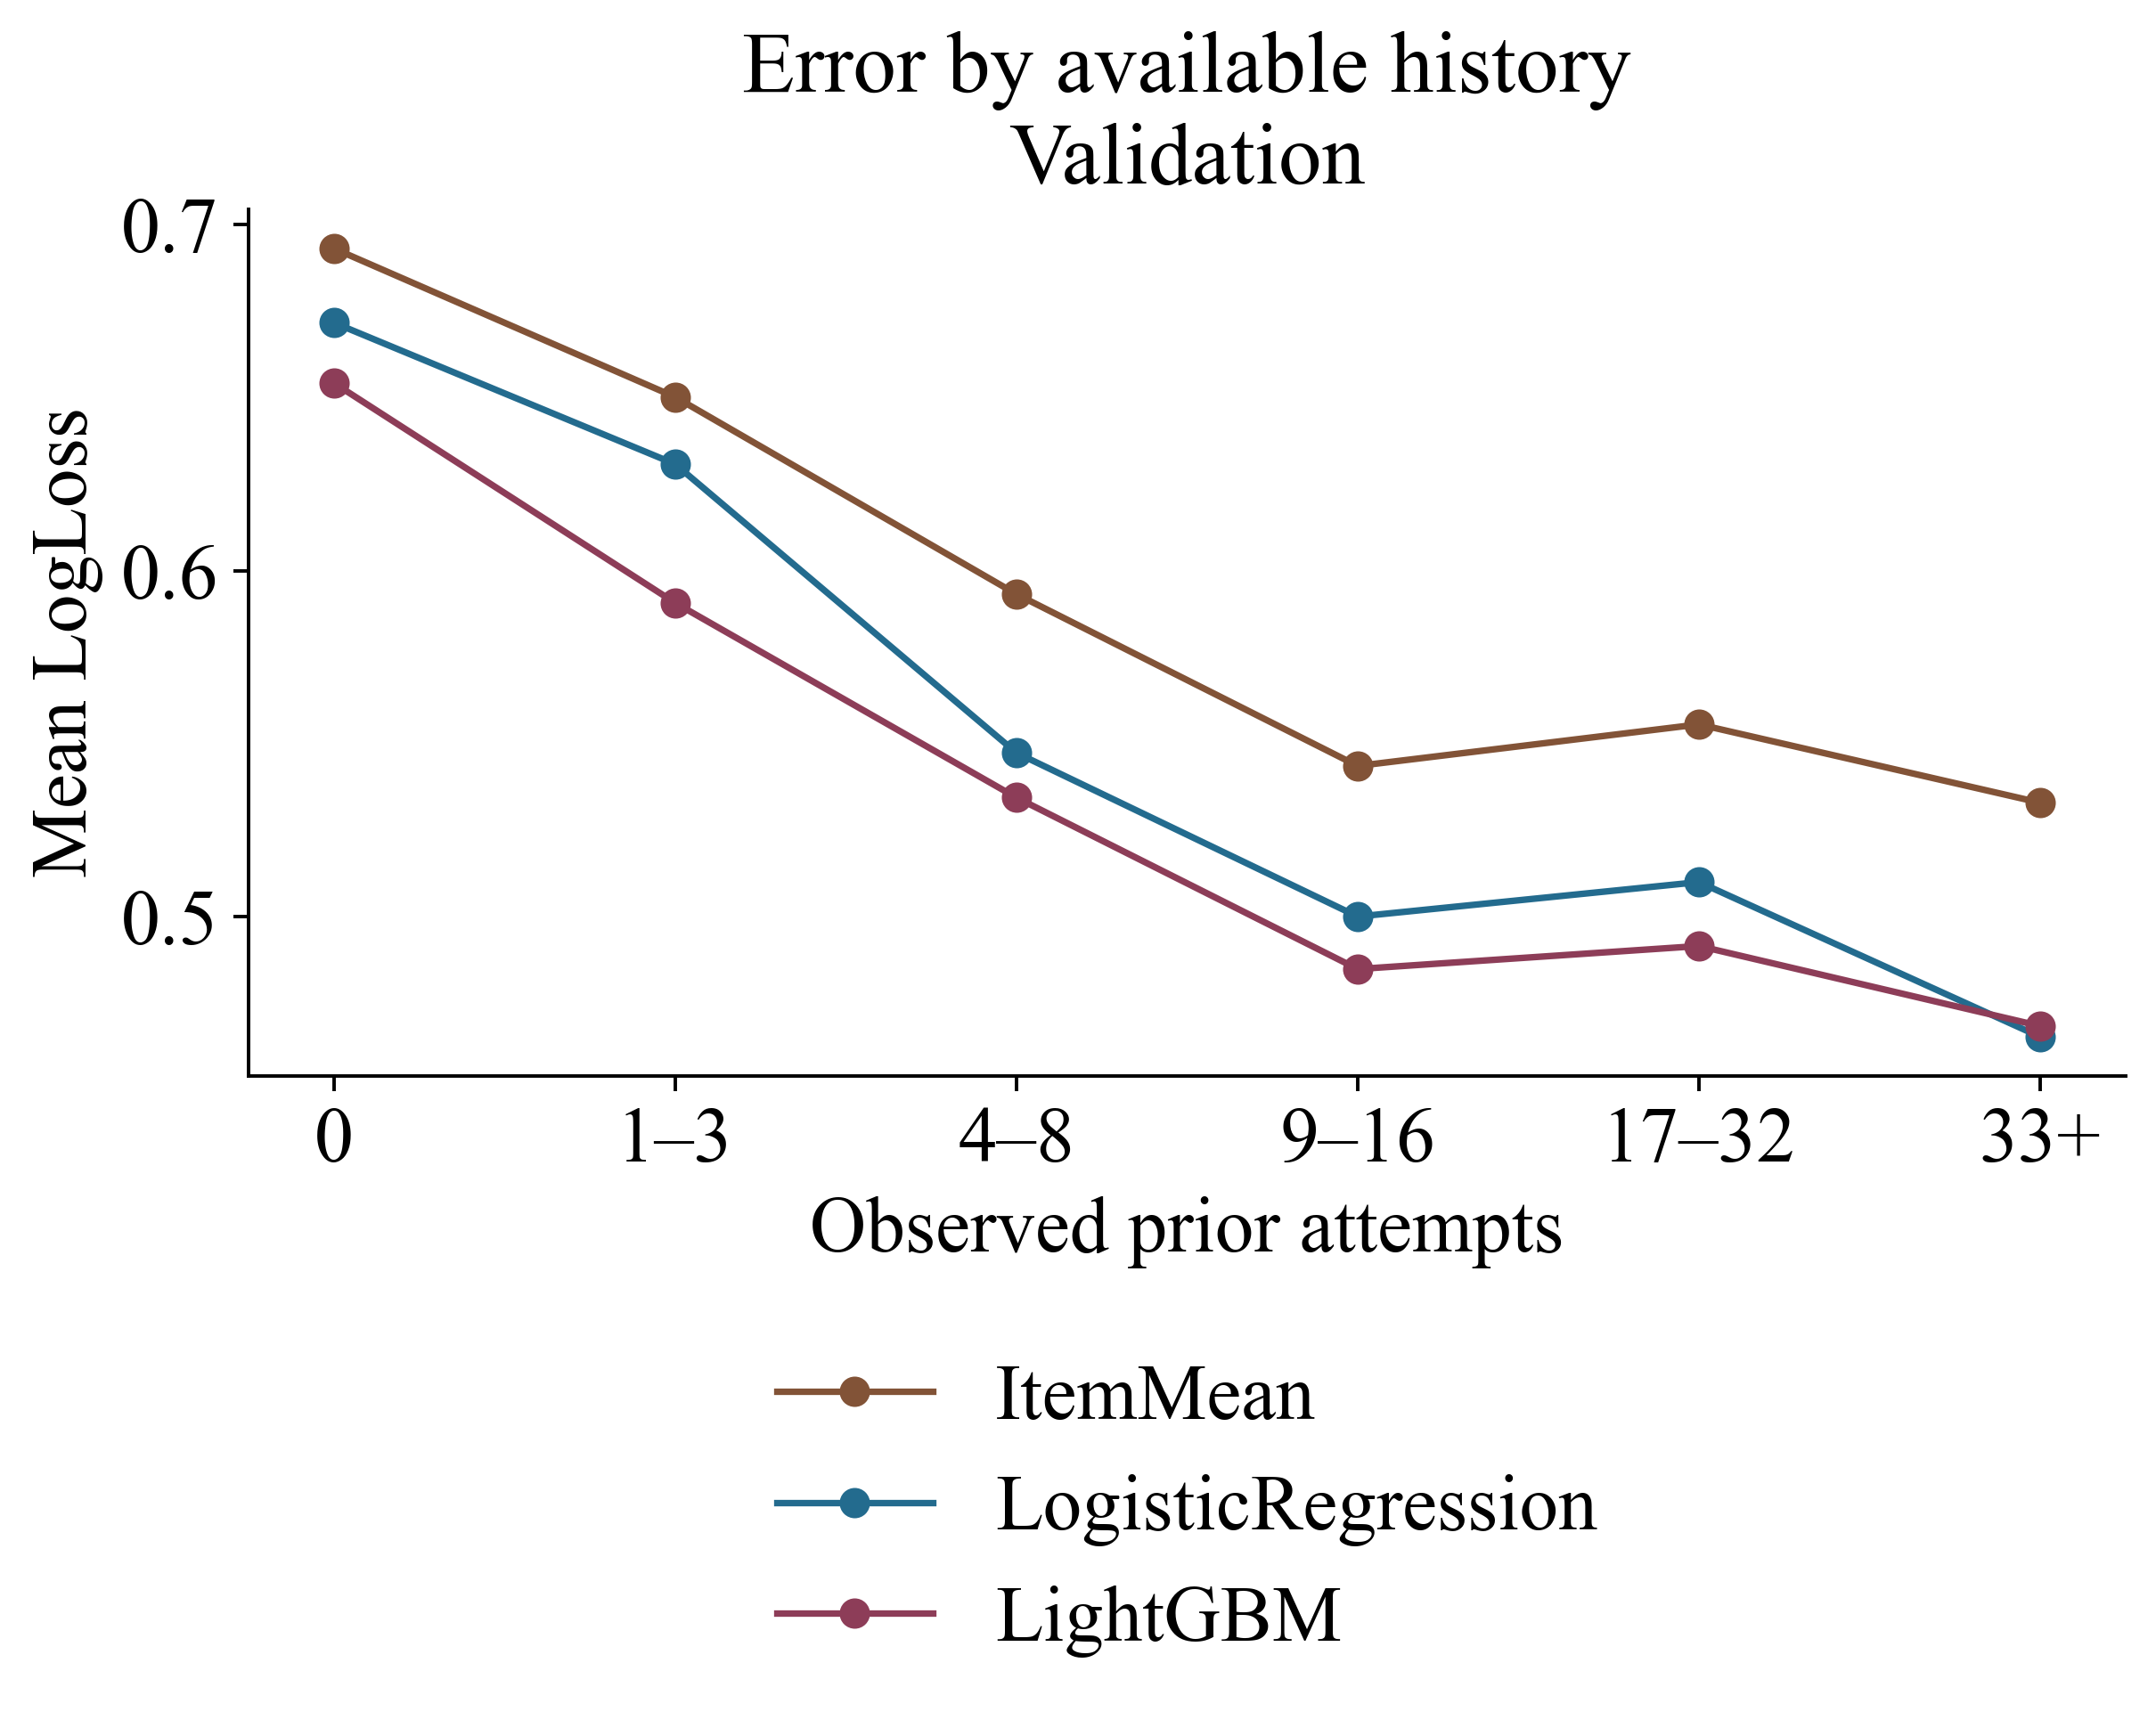

In [11]:
history_group = pd.cut(
    validation_data.history_n,
    bins=[-1, 0, 3, 8, 16, 32, np.inf],
    labels=["0", "1–3", "4–8", "9–16", "17–32", "33+"],
)
fig, ax = plt.subplots(figsize=(6.8, 5.4), layout="constrained")
regime_rows = []
for model_name, color in zip(DIAGNOSTIC_MODELS, COLORS):
    probability = (
        ensemble_validation.loc[model_name]
        .reindex(validation_data.id)
        .to_numpy()
    )
    probability = np.clip(
        probability, PROBABILITY_EPSILON, 1 - PROBABILITY_EPSILON
    )
    loss = -(
        validation_data.y * np.log(probability)
        + (1 - validation_data.y) * np.log1p(-probability)
    )
    grouped = (
        pd.DataFrame({"group": history_group, "loss": loss})
        .groupby("group", observed=False)
        .agg(n=("loss", "size"), LogLoss=("loss", "mean"))
        .reset_index()
    )
    ax.plot(
        np.arange(len(grouped)),
        grouped.LogLoss,
        color=color,
        marker="o",
        label=model_name,
    )
    grouped["Model"] = model_name
    regime_rows.append(grouped)
ax.set(
    xticks=np.arange(6),
    xticklabels=["0", "1–3", "4–8", "9–16", "17–32", "33+"],
    xlabel="Observed prior attempts",
    ylabel="Mean LogLoss",
    title="Error by available history\nValidation",
)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False)
ax.spines[["top", "right"]].set_visible(False)
pd.concat(regime_rows).to_csv(
    ROOT / "Tables/03_history_error.csv", index=False
)
save_figure(fig, "03_error_by_history")
plt.show()

**Interpretation.** The largest mean error is observed without prior history. LightGBM has lower LogLoss in the groups of up to 32 past attempts; at 33 or more, LogisticRegression is slightly better. This makes adaptive fusion of different mechanisms a testable hypothesis rather than grounds for declaring it superior in advance. The groups also differ in the composition of tasks and learners; the slope of the curve cannot be interpreted as a causal learning effect.

## Efficiency of tabular methods

Time includes fitting the transformations and estimating the parameters on the full train set. Prediction time refers to the already transformed validation set; the cost of preprocessing is not included. The size of the serialised model is not peak RAM usage. The values depend on the current load on the local computer.

In [12]:
efficiency_summary = (
    pd.DataFrame(efficiency_rows)
    .groupby(["Model", "Split", "n"], sort=False)
    .agg(
        Train_s=("Train seconds", "median"),
        Inference_s=("Prediction seconds", "median"),
        Model_MB=("Model MB", "median"),
    )
    .reset_index()
)
table(
    efficiency_summary,
    "Table 8. Measured computational efficiency",
    "03_efficiency_summary",
)

Table 8. Measured computational efficiency

,Model,Split,n,Train_s,Inference_s,Model_MB
0,LogisticRegression,Validation,23326,7.917,0.011,0.012
1,RandomForest,Validation,23326,5.909,0.100,15.429
2,XGBoost,Validation,23326,3.157,0.030,0.596
3,LightGBM,Validation,23326,2.160,0.100,0.796


**Interpretation.** Model size, training time and prediction time characterise different costs. The measurements refer to this device and the chosen implementation; inference time does not include preprocessing, and file size is not an estimate of peak RAM. Small time differences without repeated measurements of a single process should not be over-interpreted.

## Independent school branch

How strong are the initial score and regularised regression when transferring between schools? Only the 18 permitted inputs are used. The raw pre-test, Ridge on the pre-test, Ridge on all inputs and Random Forest are compared. The parameters are fixed in advance; OOF predictions are constructed leave-one-school-out over the four train schools. The splits are not mixed with the main programming task.

In [13]:
school_training = pd.read_pickle(
    ROOT / "Data/Processed/school_train.pkl"
).reset_index(drop=True)
school_validation = pd.read_pickle(
    ROOT / "Data/Processed/school_validation.pkl"
).reset_index(drop=True)
school_contract = json.loads(
    (ROOT / "Protocol/school_features.json").read_text()
)
school_features, school_target = (
    school_contract["features"],
    school_contract["target"],
)
pretest = school_contract["pretest"]


def school_pipeline(estimator, columns: list[str]):
    """Fit numeric imputation and grade encoding separately within each fold."""
    grade = "Students' grade"
    numeric = [column for column in columns if column != grade]
    transformations = [
        (
            "numeric",
            make_pipeline(
                SimpleImputer(strategy="median", add_indicator=True),
                StandardScaler(),
            ),
            numeric,
        )
    ]
    if grade in columns:
        transformations.append(
            (
                "grade",
                make_pipeline(
                    SimpleImputer(strategy="most_frequent"),
                    OneHotEncoder(
                        handle_unknown="ignore", sparse_output=False
                    ),
                ),
                [grade],
            )
        )
    return make_pipeline(ColumnTransformer(transformations), clone(estimator))


school_specs = [
    ("Pretest", None, [pretest]),
    ("RidgePretest", Ridge(alpha=10), [pretest]),
    ("RidgeFull", Ridge(alpha=10), school_features),
    (
        "RandomForest",
        RandomForestRegressor(
            n_estimators=200,
            max_depth=6,
            min_samples_leaf=15,
            n_jobs=2,
            random_state=17,
        ),
        school_features,
    ),
]
school_rows, school_prediction_rows = [], []
for name, estimator, columns in school_specs:
    out_of_fold = np.full(len(school_training), np.nan)
    for school_group in sorted(school_training.school_group.unique()):
        held_out = school_training.school_group.eq(school_group)
        if estimator is None:
            out_of_fold[held_out] = school_training.loc[held_out, pretest]
        else:
            fitted = school_pipeline(estimator, columns)
            fitted.fit(
                school_training.loc[~held_out, columns],
                school_training.loc[~held_out, school_target],
            )
            out_of_fold[held_out] = fitted.predict(
                school_training.loc[held_out, columns]
            )
    if estimator is None:
        validation_prediction = school_validation[pretest].to_numpy()
    else:
        fitted = school_pipeline(estimator, columns)
        fitted.fit(school_training[columns], school_training[school_target])
        validation_prediction = fitted.predict(school_validation[columns])
        joblib.dump(
            {"model": fitted, "features": columns},
            MODEL_DIR / f"School_{name}.joblib",
        )
    for split, frame, predicted in [
        ("Train OOF", school_training, out_of_fold),
        ("Validation", school_validation, validation_prediction),
    ]:
        predicted = np.clip(predicted, 0, 24)
        truth = frame[school_target].to_numpy()
        school_rows.append(
            {
                "Model": name,
                "Split": split,
                "n": len(frame),
                "MAE ↓": mean_absolute_error(truth, predicted),
                "RMSE ↓": np.sqrt(mean_squared_error(truth, predicted)),
                "R² ↑": r2_score(truth, predicted),
            }
        )
        school_prediction_rows.append(
            pd.DataFrame(
                {
                    "source_row": frame.source_row,
                    "school": frame.school_group,
                    "Model": name,
                    "Split": split,
                    "target": truth,
                    "predicted": predicted,
                }
            )
        )
school_results = pd.DataFrame(school_rows)
pd.concat(school_prediction_rows).to_csv(
    ROOT / "Results/03_school_predictions.csv", index=False
)
table(
    school_results,
    "Table 9. Prediction of the school outcome",
    "03_school_results",
)

Table 9. Prediction of the school outcome

,Model,Split,n,MAE ↓,RMSE ↓,R² ↑
0,Pretest,Train OOF,909,3.590,4.596,0.093
1,Pretest,Validation,157,2.752,3.640,0.299
2,RidgePretest,Train OOF,909,2.862,3.671,0.421
3,RidgePretest,Validation,157,2.107,2.694,0.616
4,RidgeFull,Train OOF,909,3.211,4.128,0.268
5,RidgeFull,Validation,157,2.211,2.761,0.597
6,RandomForest,Train OOF,909,2.940,3.770,0.389
7,RandomForest,Validation,157,2.186,2.736,0.604


**Interpretation.** On the single validation school, RidgePretest yields an MAE of about 2.107 and an RMSE of about 2.694 — better than RidgeFull and RandomForest. OOF over the four training schools also supports the simple variant. Adding questionnaire features is not yet justified by the results; group shift and the limited number of independent schools may play a role.

## Strong baselines for the subsequent comparison

Selection for further analysis is made on validation only. Differences between OOF and validation are reported separately; no family is declared best on the locked test. Contemporary sequential models will be compared on the same primary target sample.

In [14]:
selection = (
    validation_metrics.groupby(["Model", "n"], sort=False)
    .agg(
        LogLoss=("LogLoss", "mean"),
        AUROC=("AUROC", "mean"),
        AP=("AP", "mean"),
        Brier=("Brier", "mean"),
    )
    .reset_index()
)
selection = selection.sort_values("LogLoss", kind="stable").reset_index(
    drop=True
)
selection.insert(1, "Split", "Validation")
selection["Rank"] = np.arange(1, len(selection) + 1)
selection.to_csv(ROOT / "Results/03_validation_selection.csv", index=False)
table(
    selection[["Model", "Split", "n", "Rank", "LogLoss", "Brier"]],
    "Table 10. Ranking of baselines by the primary metric",
    "03_baseline_selection",
)

(ROOT / "Protocol/baseline_execution.json").write_text(
    json.dumps(
        {
            "feature_revision": contract["feature_revision"],
            "completed": True,
            "seeds": SEEDS,
        }
    )
);

Table 10. Ranking of baselines by the primary metric

,Model,Split,n,Rank,LogLoss,Brier
0,LightGBM,Validation,23326,1,0.531,0.178
1,XGBoost,Validation,23326,2,0.533,0.179
2,RandomForest,Validation,23326,3,0.542,0.182
3,LogisticRegression,Validation,23326,4,0.550,0.185
4,ItemMean,Validation,23326,5,0.589,0.202
5,GlobalMean,Validation,23326,6,0.684,0.245


**Interpretation.** For further comparison, LightGBM is retained as the strongest ML baseline, XGBoost as a close competitor and LogisticRegression as a compact interpretable control. Their validation ranking is not statistical proof of superiority on future learners.

## Boundary of the conclusions

The results characterise the archival first-run prediction problem with a known set of tasks. Family selection and the subsequent construction of the hybrid use validation; a conclusion about superiority will require a single evaluation on the locked test after the architecture has been fixed. The school branch has only four training schools and one validation school: the limited number of independent groups is not offset by a large number of learners.